# RAG Research Lab: Can We Make Retrieval-Augmented Generation Measurably Better?

**A reproducible, free-first research project** comparing BM25, dense retrieval, hybrid retrieval, and optional cross-encoder reranking on the BEIR SciFact benchmark.

**What this notebook measures**
- Recall@k
- Mean Reciprocal Rank (MRR@k)
- nDCG@k
- Retrieval latency
- Optional reranker lift
- Evidence-grounded extractive answers, plus optional local Ollama generation

**Important:** the notebook downloads a public benchmark when run. It does not contain the full SciFact dataset. Keep the benchmark's CC-BY-SA 4.0 attribution and review the dataset card before redistributing data. Results are computed on your run; no performance improvement is assumed in advance.

## Run instructions

1. Open a new Google Colab notebook and upload this `.ipynb`, or open it directly from GitHub.
2. Choose **Runtime → Change runtime type**. CPU is sufficient for the small corpus; GPU can speed up embedding/reranking.
3. Run cells from top to bottom.
4. Start with `MAX_QUERIES = 200` for a quick experiment; set it to `None` for the full test query split.
5. Results are saved under `outputs/` as CSV and JSON.

This notebook uses SciFact because it is a compact scientific claim retrieval benchmark (about 5.2k corpus documents according to its dataset card). See the dataset references in the README.

In [1]:
# Install dependencies (run once per fresh Colab session)
%pip -q install beir sentence-transformers rank-bm25 pandas numpy scikit-learn matplotlib tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.9/304.9 kB 15.2 MB/s eta 0:00:00


In [2]:
import os, json, time, math, re, warnings, subprocess, shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# For a fast smoke test use 50. For a stronger result use 200-None.
MAX_QUERIES = 200
TOP_K = 10

## 1. Download the benchmark

BEIR SciFact includes a document corpus, queries, and relevance judgments (`qrels`). The qrels are the ground truth for retrieval evaluation: a retrieved document counts as relevant only if it is labelled relevant for that query.

We use the BEIR loader rather than inventing labels. If the upstream dataset layout changes, consult the dataset card linked in the project README.

In [3]:
from beir import util
from beir.datasets.data_loader import GenericDataLoader

DATASET = "scifact"
url = f"https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/{DATASET}.zip"
data_path = util.download_and_unzip(url, "datasets")

corpus, queries, qrels = GenericDataLoader(data_folder=data_path).load(split="test")

print(f"Corpus documents: {len(corpus):,}")
print(f"Queries in test split: {len(queries):,}")
print(f"Queries with relevance labels: {len(qrels):,}")

query_ids = sorted(set(queries) & set(qrels))
if MAX_QUERIES is not None:
    query_ids = query_ids[:MAX_QUERIES]

queries_eval = {qid: queries[qid] for qid in query_ids}
qrels_eval = {qid: qrels[qid] for qid in query_ids}

print(f"Queries evaluated this run: {len(queries_eval):,}")

/usr/local/lib/python3.13/dist-packages/beir/util.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


datasets/scifact.zip:   0%|          | 0.00/2.69M [00:00<?, ?iB/s]

  0%|          | 0/5183 [00:00<?, ?it/s]

Corpus documents: 5,183
Queries in test split: 300
Queries with relevance labels: 300
Queries evaluated this run: 200


## 2. Prepare a consistent document representation

All retrieval methods use the same corpus and query set. Titles are included in document text because they often contain useful scientific context. This experiment does not tune on the evaluation labels.

In [4]:
doc_ids = list(corpus.keys())
doc_text_by_id = {}
doc_texts = [
    (str(corpus[d].get("title", "") or "") + "\n" +
     str(corpus[d].get("text", "") or "")).strip()
    for d in doc_ids
]
doc_text_by_id = dict(zip(doc_ids, doc_texts))
query_ids_ordered = list(queries_eval.keys())
query_texts = [queries_eval[qid] for qid in query_ids_ordered]

print("Example query:", query_texts[0])
print("Example document:", doc_texts[0][:350], "...")

Example query: 0-dimensional biomaterials show inductive properties.
Example document: Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.
Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (M ...


## 3. Baseline A — BM25 lexical retrieval

BM25 is a strong, transparent lexical baseline. It is useful for exact terms, acronyms and rare words, but can miss semantically related documents that use different wording.

In [6]:
from rank_bm25 import BM25Okapi

def tokenize(text):
    # Using a raw string for the regular expression so backslashes are not treated as escape characters
    return re.findall(r"(?u)\b\w+\b", text.lower())

t0 = time.perf_counter()
tokenized_corpus = [tokenize(t) for t in doc_texts]
bm25 = BM25Okapi(tokenized_corpus)
bm25_build_seconds = time.perf_counter() - t0

def bm25_search(query, k=TOP_K):
    scores = bm25.get_scores(tokenize(query))
    idx = np.argsort(scores)[::-1][:k]
    return [(doc_ids[i], float(scores[i])) for i in idx]

bm25_results = {}
bm25_latencies = []
for qid, q in queries_eval.items():
    t0 = time.perf_counter()
    bm25_results[qid] = bm25_search(q, TOP_K)
    bm25_latencies.append(time.perf_counter() - t0)

print(f"BM25 index build: {bm25_build_seconds:.2f}s")
print(f"BM25 mean query latency: {np.mean(bm25_latencies)*1000:.2f} ms")

BM25 index build: 1.06s
BM25 mean query latency: 37.21 ms


## 5. Evaluation metrics

We report:
- **Recall@k:** fraction of known relevant documents retrieved in the top k.
- **MRR@k:** reciprocal rank of the first relevant result, averaged over queries.
- **nDCG@k:** ranking quality with graded relevance discounts.

These are retrieval metrics, not proof that generated answers are correct. Results depend on the selected query subset and dataset labels.

In [8]:
def evaluate_run(results, qrels, k=10):
    recalls, reciprocal_ranks, ndcgs = [], [], []
    for qid, rels in qrels.items():
        relevant = {doc_id for doc_id, score in rels.items() if score > 0}
        ranked = [doc_id for doc_id, _ in results.get(qid, [])[:k]]
        hits = [1 if d in relevant else 0 for d in ranked]

        recalls.append(len(set(ranked) & relevant) / max(1, len(relevant)))

        rr = 0.0
        for rank, hit in enumerate(hits, start=1):
            if hit:
                rr = 1.0 / rank
                break
        reciprocal_ranks.append(rr)

        gains = np.array([rels.get(d, 0) for d in ranked], dtype=float)
        discounts = 1.0 / np.log2(np.arange(2, len(gains) + 2))
        dcg = float(np.sum((2**gains - 1) * discounts))
        ideal = sorted([float(v) for v in rels.values()], reverse=True)[:k]
        ideal_gains = np.array(ideal, dtype=float)
        ideal_discounts = 1.0 / np.log2(np.arange(2, len(ideal_gains) + 2))
        idcg = float(np.sum((2**ideal_gains - 1) * ideal_discounts))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

    return {
        f"Recall@{k}": float(np.mean(recalls)),
        f"MRR@{k}": float(np.mean(reciprocal_ranks)),
        f"nDCG@{k}": float(np.mean(ndcgs)),
        "queries": len(qrels),
    }

metrics = pd.DataFrame([
    {"method": "BM25", **evaluate_run(bm25_results, qrels_eval, TOP_K),
     "mean_search_latency_ms": float(np.mean(bm25_latencies)*1000)},
    {"method": "Dense MiniLM", **evaluate_run(dense_results, qrels_eval, TOP_K),
     "mean_search_latency_ms": float(np.mean(dense_latencies)*1000)},
])
metrics

,method,Recall@10,MRR@10,nDCG@10,queries,mean_search_latency_ms
0,BM25,0.776,0.626097,0.657268,200,37.208120
1,Dense MiniLM,0.793,0.636603,0.671586,200,0.827862


## 6. Hybrid retrieval — combine lexical and dense rankings

A simple, robust approach is Reciprocal Rank Fusion (RRF). It combines ranks instead of directly comparing BM25 and cosine scores, which are on different scales.

We retrieve a larger candidate set from each method and fuse the rankings. This is a baseline fusion method; compare it fairly against BM25 and dense retrieval.

In [9]:
FUSION_K = 60
CANDIDATE_K = 50

def rrf_fuse(result_lists, k=10, rrf_k=60):
    fused = defaultdict(float)
    for result_list in result_lists:
        for rank, (doc_id, score) in enumerate(result_list, start=1):
            fused[doc_id] += 1.0 / (rrf_k + rank)
    return sorted(fused.items(), key=lambda x: x[1], reverse=True)[:k]

bm25_candidates = {}
dense_candidates = {}
for qid, q in queries_eval.items():
    bm25_candidates[qid] = bm25_search(q, CANDIDATE_K)
for i, qid in enumerate(query_ids_ordered):
    dense_candidates[qid] = dense_search_by_vector(query_embeddings[i], CANDIDATE_K)

hybrid_results = {
    qid: rrf_fuse([bm25_candidates[qid], dense_candidates[qid]], TOP_K, FUSION_K)
    for qid in query_ids_ordered
}

metrics = pd.concat([
    metrics,
    pd.DataFrame([{
        "method": "Hybrid RRF",
        **evaluate_run(hybrid_results, qrels_eval, TOP_K),
        "mean_search_latency_ms": None
    }])
], ignore_index=True)
metrics

/tmp/ipykernel_3391/262152171.py:23: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics = pd.concat([


,method,Recall@10,MRR@10,nDCG@10,queries,mean_search_latency_ms
0,BM25,0.776000,0.626097,0.657268,200,37.208120
1,Dense MiniLM,0.793000,0.636603,0.671586,200,0.827862
2,Hybrid RRF,0.838833,0.671107,0.706665,200,NaN


## 7. Optional — cross-encoder reranking

A cross-encoder scores each query-document pair jointly and can improve ordering, at additional compute cost. It reranks the top candidates from hybrid retrieval; it does not search the full corpus.

If this step is too slow on CPU, skip it or reduce `MAX_QUERIES` and `CANDIDATE_K`.

In [10]:
RUN_RERANKER = True  # set False for a faster CPU-only run

if RUN_RERANKER:
    from sentence_transformers import CrossEncoder
    RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
    reranker = CrossEncoder(RERANK_MODEL, max_length=512)

    reranked_results = {}
    rerank_latencies = []
    for qid, q in queries_eval.items():
        candidates = hybrid_results[qid]
        pairs = [(q, doc_text_by_id[doc_id]) for doc_id, _ in candidates]
        t0 = time.perf_counter()
        scores = reranker.predict(pairs, show_progress_bar=False)
        rerank_latencies.append(time.perf_counter() - t0)
        reranked_results[qid] = sorted(
            [(candidates[i][0], float(scores[i])) for i in range(len(candidates))],
            key=lambda x: x[1], reverse=True
        )[:TOP_K]

    metrics = pd.concat([
        metrics,
        pd.DataFrame([{
            "method": "Hybrid + cross-encoder",
            **evaluate_run(reranked_results, qrels_eval, TOP_K),
            "mean_search_latency_ms": float(np.mean(rerank_latencies)*1000)
        }])
    ], ignore_index=True)
else:
    reranked_results = None

metrics

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

,method,Recall@10,MRR@10,nDCG@10,queries,mean_search_latency_ms
0,BM25,0.776000,0.626097,0.657268,200,37.208120
1,Dense MiniLM,0.793000,0.636603,0.671586,200,0.827862
2,Hybrid RRF,0.838833,0.671107,0.706665,200,NaN
3,Hybrid + cross-encoder,0.838833,0.667573,0.703426,200,3006.424135


## 8. Visualize and export evaluation outputs

Do not interpret a small score difference as meaningful without checking sample size, query-level variation and failure cases. These metrics are descriptive results for this run, not universal model rankings.

,method,Recall@10,MRR@10,nDCG@10,queries,mean_search_latency_ms
0,BM25,0.7760,0.6261,0.6573,200,37.2081
1,Dense MiniLM,0.7930,0.6366,0.6716,200,0.8279
2,Hybrid RRF,0.8388,0.6711,0.7067,200,NaN
3,Hybrid + cross-encoder,0.8388,0.6676,0.7034,200,3006.4241


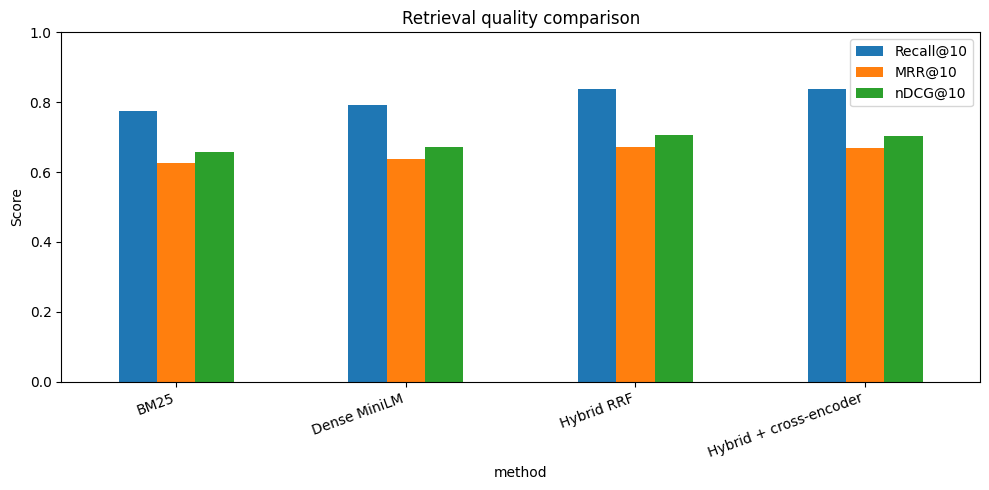

Saved metrics and run configuration to /content/outputs


In [11]:
display(metrics.round(4))

plot_metrics = ["Recall@10", "MRR@10", "nDCG@10"]
ax = metrics.set_index("method")[plot_metrics].plot(kind="bar", figsize=(10, 5))
ax.set_title("Retrieval quality comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "retrieval_metrics.png", dpi=160)
plt.show()

metrics.to_csv(OUTPUT_DIR / "retrieval_metrics.csv", index=False)
with open(OUTPUT_DIR / "run_config.json", "w") as f:
    json.dump({
        "dataset": "BEIR SciFact",
        "max_queries": MAX_QUERIES,
        "evaluated_queries": len(queries_eval),
        "top_k": TOP_K,
        "embedding_model": EMBED_MODEL,
        "reranker_enabled": RUN_RERANKER,
        "seed": SEED
    }, f, indent=2)
print("Saved metrics and run configuration to", OUTPUT_DIR.resolve())

## 9. Inspect failure cases

Look at queries where a method missed all known relevant documents. Failure analysis is essential: aggregate metrics alone do not tell you whether the problem is terminology, query ambiguity, missing corpus coverage, chunking or ranking.

In [14]:
def missed_queries(results, qrels, query_map, limit=10, k=TOP_K):
    rows = []
    for qid, rels in qrels.items():
        relevant = {d for d, score in rels.items() if score > 0}
        ranked = [d for d, _ in results.get(qid, [])[:k]]
        if not (set(ranked) & relevant):
            rows.append({
                "query_id": qid,
                "query": query_map[qid],
                "relevant_doc_ids": ", ".join(sorted(relevant)),
                "retrieved_doc_ids": ", ".join(ranked)
            })
    return pd.DataFrame(rows).head(limit)

query_map = {qid: queries_eval[qid] for qid in query_ids_ordered}
failures = missed_queries(hybrid_results, qrels_eval, query_map, limit=20)
failures.to_csv(OUTPUT_DIR / "hybrid_failure_cases.csv", index=False)
failures

,query_id,query,relevant_doc_ids,retrieved_doc_ids
0,1,0-dimensional biomaterials show inductive prop...,31715818,"803312, 25404036, 10608397, 29638116, 43385013..."
1,1049,Ribosomopathies have a low degree of cell and ...,12486491,"24737389, 8925851, 7487927, 26112624, 6670101,..."
2,1110,Suboptimal nutrition is not predictive of chro...,13770184,"49429882, 75636923, 70704988, 756887, 20288322..."
3,1175,The PPR MDA5 has two N-terminal CARD domains.,31272411,"16058322, 22191759, 612002, 4321947, 9169645, ..."
4,1179,The PRR MDA5 has a central DExD/H RNA helices ...,31272411,"20725212, 12149169, 1383826, 10627801, 1541987..."
5,1199,The benefits of colchicine were achieved with ...,16760369,"7454794, 21557614, 40156901, 4687948, 5698494,..."
6,1200,The binding orientation of the ML-SA1 activato...,3441524,"25682129, 493346, 4391685, 21219071, 7878807, ..."
7,1213,The deregulated and prolonged activation of mo...,14407673,"17934603, 36444198, 14492339, 7948486, 2149849..."
8,1221,The genomic aberrations found in matasteses ar...,19736671,"16732790, 11861374, 40900242, 7020505, 4467430..."
9,1226,The loss of the TET protein functions may have...,13777138,"11951999, 24731248, 2405259, 25832301, 1508177..."


## 10. Inspect a query and its evidence

This helper displays the retrieved document IDs, ranking scores, titles and snippets. It is useful for manual error analysis and for the technical report.

In [12]:
def inspect_query(qid, results, k=5):
    if qid not in queries_eval:
        raise KeyError(f"Unknown query id: {qid}")
    rows = []
    for rank, (doc_id, score) in enumerate(results[qid][:k], start=1):
        d = corpus[doc_id]
        rows.append({
            "rank": rank, "doc_id": doc_id, "score": round(float(score), 5),
            "title": d.get("title", ""),
            "text_snippet": (d.get("text", "") or "")[:500],
            "is_relevant": qrels_eval[qid].get(doc_id, 0) > 0
        })
    print("QUERY:", queries_eval[qid])
    return pd.DataFrame(rows)

inspect_query(query_ids_ordered[0], hybrid_results, k=5)

QUERY: 0-dimensional biomaterials show inductive properties.


,rank,doc_id,score,title,text_snippet,is_relevant
0,1,803312,0.02692,Cerebral organoids model human brain developme...,The complexity of the human brain has made it ...,False
1,2,25404036,0.02296,Three-Dimensional Modeling and Quantitative An...,Gap junctions play a fundamental role in inter...,False
2,3,10608397,0.01639,High-performance neuroprosthetic control by an...,BACKGROUND Paralysis or amputation of an arm r...,False
3,4,29638116,0.01639,Complex Tissue and Disease Modeling using hiPSCs.,Defined genetic models based on human pluripot...,False
4,5,43385013,0.01613,Epithelial and mesenchymal subpopulations with...,It has been proposed that epithelial-mesenchym...,False


## 11. Export a compact sample dataset and predictions

We do not redistribute the complete benchmark here. This cell exports a small sample of the benchmark records and predictions for local inspection. Keep dataset attribution and licence terms when publishing.

In [13]:
sample_rows = []
for qid in query_ids_ordered[:20]:
    sample_rows.append({
        "query_id": qid,
        "query": queries_eval[qid],
        "relevant_doc_ids": json.dumps({
            d: int(s) for d, s in qrels_eval[qid].items()
        }),
        "hybrid_top10": json.dumps([
            {"doc_id": d, "score": float(s)} for d, s in hybrid_results[qid]
        ])
    })
pd.DataFrame(sample_rows).to_csv(OUTPUT_DIR / "sample_queries_and_predictions.csv", index=False)

# Save a few corpus records as a tiny inspectable sample; source remains the official dataset.
sample_docs = [
    {"_id": d, "title": corpus[d].get("title", ""), "text": corpus[d].get("text", "")}
    for d in doc_ids[:20]
]
with open(OUTPUT_DIR / "sample_corpus.jsonl", "w", encoding="utf-8") as f:
    for row in sample_docs:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Files written:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name, f"({p.stat().st_size:,} bytes)")

Files written:
- retrieval_metrics.csv (414 bytes)
- retrieval_metrics.png (59,222 bytes)
- run_config.json (201 bytes)
- sample_corpus.jsonl (29,790 bytes)
- sample_queries_and_predictions.csv (14,365 bytes)


## 12. Create a run report from actual metrics

This generates a Markdown report with the scores measured in this session. Review it before publishing, especially the run configuration and limitations.

In [15]:
best_recall = metrics.sort_values("Recall@10", ascending=False).iloc[0]
best_ndcg = metrics.sort_values("nDCG@10", ascending=False).iloc[0]

report = f'''# RAG Research Lab — Run Report

## Setup
- Dataset: BEIR SciFact (test split)
- Queries evaluated: {len(queries_eval)}
- Corpus documents: {len(corpus)}
- Embedding model: `{EMBED_MODEL}`
- Top-k: {TOP_K}
- Reranker enabled: {RUN_RERANKER}

## Results

{metrics.round(4).to_markdown(index=False)}

## Observations
- Best Recall@10 in this run: **{best_recall["method"]}** ({best_recall["Recall@10"]:.4f})
- Best nDCG@10 in this run: **{best_ndcg["method"]}** ({best_ndcg["nDCG@10"]:.4f})

These are results from this specific run and query subset. They are not claims about all RAG workloads.

## Limitations
- SciFact is a scientific claim retrieval benchmark; findings may not generalize to enterprise documents or other domains.
- Retrieval relevance labels are incomplete by nature; an unlabelled document is not necessarily irrelevant.
- Latency depends on runtime, hardware, warm-up, batch size and concurrent load.
- This report evaluates retrieval. It does not establish generated answer correctness.
- Reranking compares only a candidate set retrieved by hybrid RRF.

## Next experiments
1. Repeat with `MAX_QUERIES = None`.
2. Compare another embedding model.
3. Vary top-k and candidate count.
4. Inspect failures by query type.
5. Add a labelled answer-quality benchmark before drawing conclusions about generation.
'''
(OUTPUT_DIR / "technical_report.md").write_text(report, encoding="utf-8")
print(report)

# RAG Research Lab — Run Report

## Setup
- Dataset: BEIR SciFact (test split)
- Queries evaluated: 200
- Corpus documents: 5183
- Embedding model: `sentence-transformers/all-MiniLM-L6-v2`
- Top-k: 10
- Reranker enabled: True

## Results

| method                 |   Recall@10 |   MRR@10 |   nDCG@10 |   queries |   mean_search_latency_ms |
|:-----------------------|------------:|---------:|----------:|----------:|-------------------------:|
| BM25                   |      0.776  |   0.6261 |    0.6573 |       200 |                  37.2081 |
| Dense MiniLM           |      0.793  |   0.6366 |    0.6716 |       200 |                   0.8279 |
| Hybrid RRF             |      0.8388 |   0.6711 |    0.7067 |       200 |                 nan      |
| Hybrid + cross-encoder |      0.8388 |   0.6676 |    0.7034 |       200 |                3006.42   |

## Observations
- Best Recall@10 in this run: **Hybrid + cross-encoder** (0.8388)
- Best nDCG@10 in this run: **Hybrid RRF** (0.7067)

These a